In [1]:
import matplotlib.pyplot as plt
from algorithms.tss_file import TSSFile
import os

In [2]:
def find_file(filename, search_dir):
    for root, dirs, files in os.walk(search_dir):
        if filename in files:
            return root
    return None

In [3]:
folder = r'Y:\TESTDATA\DP\2026\09\01'
tss_file = 'Tek20260901T171146.tss'
path = find_file(tss_file, folder)
tss = TSSFile(path, tss_file, source='Local')
channel_labels = tss.channel_labels
num = len(channel_labels.keys())
print(channel_labels)

{'ch1': 'VGO_LS', 'ch2': 'Is', 'ch3': 'Vd', 'ch4': 'VGO_HS', 'ch5': 'FLT', 'ch7': 'IG', 'ch8': 'IL'}


1


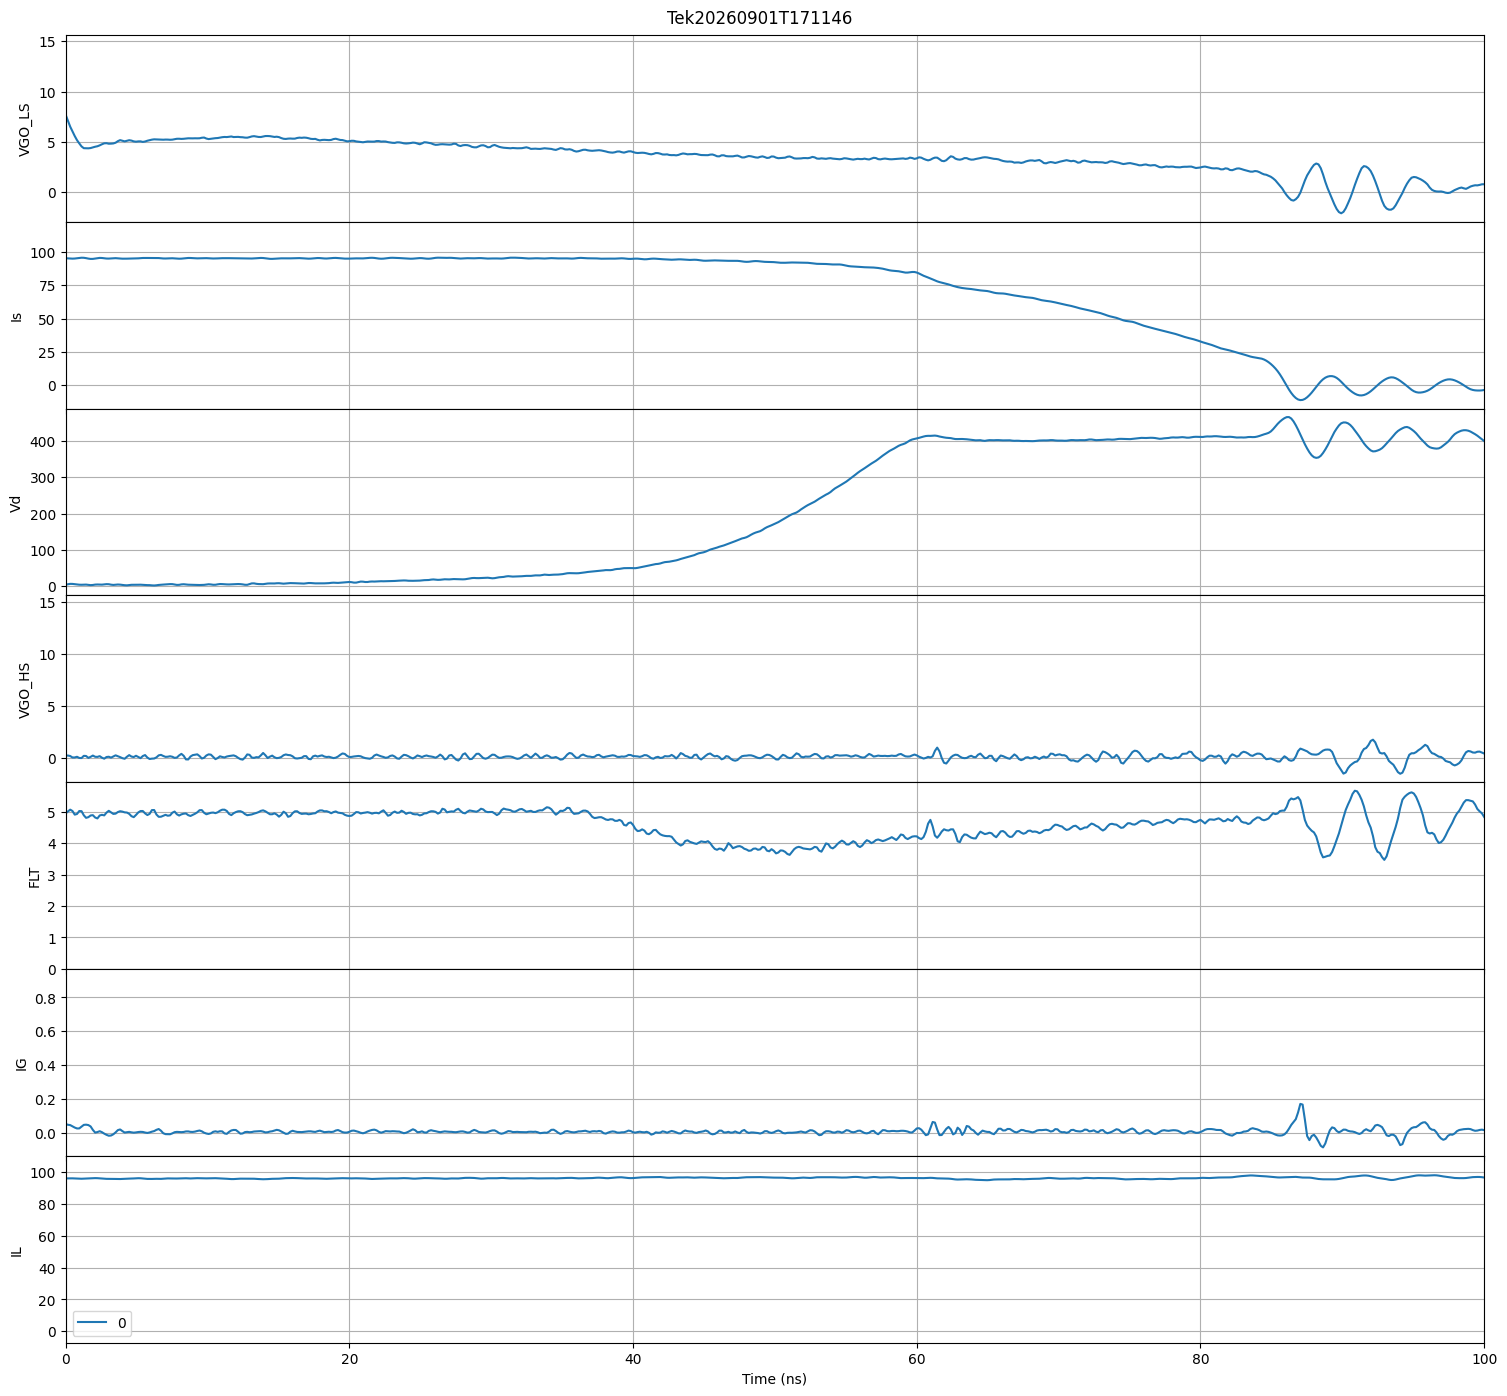

In [13]:
fig, axs = plt.subplots(num, 1, sharex=True, figsize=(15, num*2))
fig.suptitle(tss_file[:-4])
fig.tight_layout()
fig.subplots_adjust(hspace=0)
time1 = tss.waveforms[list(channel_labels.keys())[0]].time_for_frame()*1e9
print(tss.waveforms[list(channel_labels.keys())[0]].frame_count)

for i in [0]:
    index = 0
    for channel in channel_labels.keys():
        values = tss.waveforms[channel].values_for_frame(i)
        axs[index].plot(time1, values, label=i)
        axs[index].set_ylabel(channel_labels[channel])
        axs[index].grid(True)
        index += 1

plt.legend()
plt.xlabel('Time (ns)')
plt.xlim([0, 100])
plt.legend(loc='best')
plt.show()

In [8]:
from algorithms.wfm_edge import WFM_edge
import numpy as np
time = tss.waveforms[list(channel_labels.keys())[0]].time_for_frame()
is_values = tss.waveforms['ch2'].values_for_frame(0)
is_edges = WFM_edge(is_values, time, falling_edge_number=2,
                            sigma=100)
idx_off_1 = is_edges.get_edge(1, 'falling', 99)['thresh_idx']
idx_off_2 = is_edges.get_edge(1, 'falling', 1)['thresh_idx']
time_turn_off = time[idx_off_1:idx_off_2]
is_turn_off = is_values[idx_off_1:idx_off_2]
didt_off = np.gradient(is_turn_off, time_turn_off)

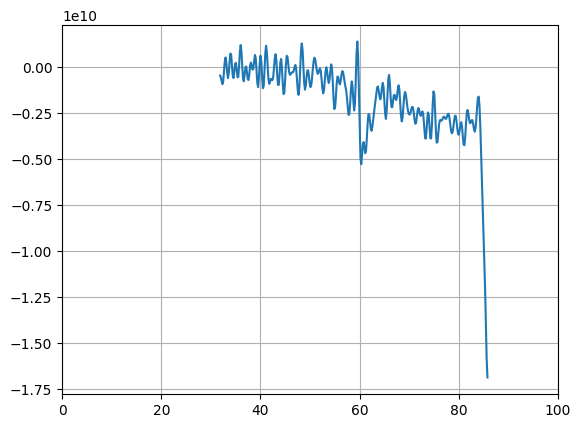

20.703124999999996


In [19]:
plt.plot(time_turn_off*1e9, didt_off)
plt.xlim([0, 100])
plt.grid()
plt.show()

didt_off_peak = min(didt_off)
idx = np.where(didt_off == didt_off_peak)[0][0]

while didt_off[idx-1] > didt_off[idx] and idx >= 2:
    idx -= 1

print(is_turn_off[idx])